# Notebook 16a — Manuscript figures and tables: corpus, measures, checks, courts

Added November 2026 for the law-review manuscript (*Common or Characteristic? An Empirical Method for Scènes à Faire*). This notebook draws every figure and writes every small table for Part III (the method) and Part IV, sections A to C (the two measures, the checks on them, the court record), in the single style defined in `saf_style.py`. Notebook 16b does the same for Part IV, sections E and F, and the Study 1 figures come from `Analysis/study1_analysis/study1_figures.Rmd`.

It fits no new models and calls no language model. It reads the saved outputs of Notebooks 01c, 02, 02b, 03, 03b, 04, 05, 07b, 07c, 10 and 14, recomputes what the May 2026 draft computed on the composite score on the two measures instead, and prints the numbers next to each figure. It writes figures (PDF and 300-dpi PNG, named `fig_*`) to the manuscript's `figures/` folder and tables (`T-*.tex`) to its `tables/` folder. It does not touch the talk's figures.

The style rules: prevalence is blue and distinctiveness red in every figure; everything else is gray, and a light gray marks values that are unreliable or filtered out; intervals are black; plots are upright; there are no figure titles, because the manuscript's captions carry them.

In [1]:
import os, re, sys, json, shutil, tempfile
from pathlib import Path
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from matplotlib.patches import FancyBboxPatch, Patch
from scipy import stats

try:
    from google.colab import drive  # type: ignore
    drive.mount('/content/drive')
except Exception:
    pass

_CANDS = [Path('/content/drive/MyDrive/DGK Lab/Reasoning Lab/DGK Lab - Scene A Faire Computational'),
          Path('/Users/USER/Library/CloudStorage/GoogleDrive-ACCOUNT/My Drive/DGK Lab/Reasoning Lab/'
               'DGK Lab - Scene A Faire Computational'),
          Path.cwd().parent.parent, Path.cwd().parent]
PROJECT_ROOT = next(c for c in _CANDS if (c / 'Analysis' / 'v4_rebuild').exists())
sys.path.insert(0, str(PROJECT_ROOT / 'Analysis' / 'notebooks'))
import saf_style as S
S.use()
V4 = PROJECT_ROOT / 'Analysis' / 'v4_rebuild'
DATA = PROJECT_ROOT / 'Data'
FIG = S.manuscript_figures_dir(PROJECT_ROOT)
TAB = FIG.parent / 'tables'
TAB.mkdir(exist_ok=True)
TMP = Path(tempfile.mkdtemp())
def read_parquet(p, **kw):
    local = TMP / p.name          # Drive sometimes serves partial parquet files; read a local copy
    shutil.copy(p, local)
    return pd.read_parquet(local, **kw)
def save(fig, name):
    S.save(fig, name, FIG)
    print('saved', name)

BLUE, RED, GRAY, LIGHT = S.PREVALENCE, S.DISTINCTIVENESS, S.NEUTRAL, S.LIGHT
SEED = 20260219
SIX = ['Western', 'Horror', 'Science Fiction', 'Crime', 'Fantasy', 'Comedy']
LAB = {'prevalence': 'Prevalence', 'distinctiveness': 'Distinctiveness', 'collocation': 'Collocation',
       'tfidf': 'TF-IDF', 'g2': "Dunning's G²", 'composite': 'Composite'}
COL = {'prevalence': BLUE, 'distinctiveness': RED}
def color_of(k): return COL.get(k, GRAY)

def mean_ci(v):
    # 95% t interval for a mean across genres
    v = np.asarray(v, float); h = stats.t.ppf(0.975, len(v) - 1) * v.std(ddof=1) / np.sqrt(len(v))
    return v.mean() - h, v.mean() + h
def wilson(k, n, z=1.96):
    k, n = np.asarray(k, float), np.asarray(n, float)
    p = k / n; den = 1 + z * z / n
    mid = (p + z * z / (2 * n)) / den; half = z * np.sqrt(p * (1 - p) / n + z * z / (4 * n * n)) / den
    return mid - half, mid + half
def rotate(ax, deg=45, size=None):
    plt.setp(ax.get_xticklabels(), rotation=deg, ha='right', rotation_mode='anchor', **({'fontsize': size} if size else {}))

def tex_escape(s):
    return (str(s).replace('\\', r'\textbackslash{}').replace('&', r'\&').replace('%', r'\%')
            .replace('_', r'\_').replace('#', r'\#').replace('$', r'\$'))
def write_table(name, caption, label, colspec, header, rows, note, size=r'\small'):
    # Small upright booktabs table with a footnote-size note underneath (house style of the manuscript).
    body = '\n'.join(' & '.join(r) + r' \\' for r in rows)
    tex = (r'\begin{table}[htbp]' '\n' r'\centering' '\n' rf'\caption{{{caption}}}' '\n' rf'\label{{{label}}}' '\n'
           f'{size}\n' rf'\begin{{tabular}}{{{colspec}}}' '\n' r'\toprule' '\n' + ' & '.join(header) + r' \\' '\n'
           r'\midrule' '\n' + body + '\n' r'\bottomrule' '\n' r'\end{tabular}' '\n\n' r'\medskip' '\n'
           r'\begin{minipage}{0.95\textwidth}\footnotesize' '\n' rf'\emph{{Note:}} {note}' '\n' r'\end{minipage}' '\n'
           r'\end{table}' '\n')
    (TAB / f'{name}.tex').write_text(tex)
    print('wrote table', name)
    return tex
print('project root:', PROJECT_ROOT); print('figures ->', FIG); print('tables  ->', TAB)

project root: /Users/USER/Library/CloudStorage/GoogleDrive-ACCOUNT/My Drive/DGK Lab/Reasoning Lab/DGK Lab - Scene A Faire Computational
figures -> /Users/USER/Library/CloudStorage/GoogleDrive-ACCOUNT/My Drive/DGK Lab/Reasoning Lab/DGK Lab - Scene A Faire Computational/Docs/Writing/manuscript/Scene A Faire Computational/figures
tables  -> /Users/USER/Library/CloudStorage/GoogleDrive-ACCOUNT/My Drive/DGK Lab/Reasoning Lab/DGK Lab - Scene A Faire Computational/Docs/Writing/manuscript/Scene A Faire Computational/tables


## Load the shared tables

`stockiness_long_classified.parquet` is the scored table (one row per feature, grammatical type and genre, after the 10/5 filter). The narrative set is the classifier's story features minus Notebook 09's franchise blocklist, which gives the 17,965 (feature, type) pairs the paper reports.

In [2]:
FRANCHISE_BLOCKLIST = {
    'stooge', 'stooges', 'panther', 'coyote', 'road runner', 'roadrunner', 'tasmanian devil',
    'wabbit', 'daffy', 'felix the cat', 'speedy gonzales', 'mickey mouse', 'donald duck',
    'enterprise', 'enterprise crew', 'shuttlecraft', 'spider man', 'spider-man', 'spiderman', 'batman', 'superman',
    'wonder woman', 'james bond', 'indiana jones', 'terminator', 'hobbit',
}   # copied from Notebook 09 (and Notebook 10, which checks the two copies agree)
sl = read_parquet(V4 / '03b_classification' / 'stockiness_long_classified.parquet')
sl['narrative'] = sl['is_narrative_element'] & ~sl['element'].isin(FRANCHISE_BLOCKLIST)
sl.loc[sl['element'].isin(FRANCHISE_BLOCKLIST), 'element_taxonomy'] = 'character_name'
pairs = sl[['element', 'element_type', 'element_taxonomy', 'narrative']].drop_duplicates(['element', 'element_type'])
n_pairs, n_narr = len(pairs), int(pairs['narrative'].sum())
print(f'{len(sl):,} cells; {n_pairs:,} (feature, type) pairs after the filter; {n_narr:,} narrative ({100 * n_narr / n_pairs:.1f}%)')
assert n_pairs == 27212 and n_narr == 17965, (n_pairs, n_narr)
GEN = sorted(sl['genre'].unique())
U = read_parquet(V4 / '01c_union' / 'movies_union.parquet')
genre_films = pd.Series([g for gs in U['genres_canonical'] for g in gs]).value_counts()
print(genre_films.to_string())

345,366 cells; 27,212 (feature, type) pairs after the filter; 17,965 narrative (66.0%)


Drama              22364
Comedy             14724
Romance             8220
Action              7775
Thriller            7447
Adventure           6146
Crime               5564
Horror              4363
Family              4164
Music               2926
History             2882
Animation           2835
Mystery             2681
Science Fiction     2590
Fantasy             2429
War                 1658
Western             1362


# Part III. The method

## Figure: the pipeline

Drawn from code: each box is a stage. The boxes name stages only (no notebook numbers): the manuscript cites data and method, not scripts.

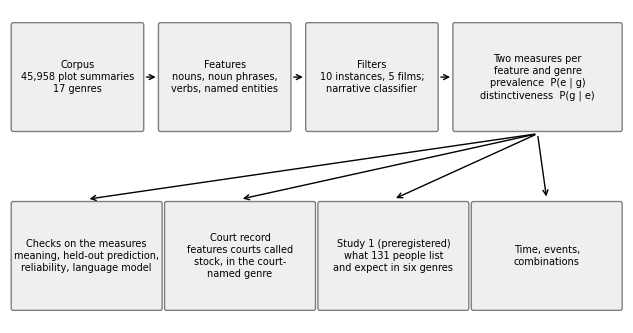

saved fig_pipeline


In [3]:
fig, ax = plt.subplots(figsize=S.size(1.0, 3.4))
ax.set_xlim(0, 100); ax.set_ylim(0, 42); ax.axis('off')   # a diagram, not a plot: no axes
def box(x, y, w, h, text, face='#efefef'):
    ax.add_patch(FancyBboxPatch((x, y), w, h, boxstyle='round,pad=0.3', fc=face, ec=GRAY, lw=1))
    ax.text(x + w / 2, y + h / 2, text, ha='center', va='center', fontsize=7, linespacing=1.25)
def arrow(x0, y0, x1, y1):
    ax.annotate('', xy=(x1, y1), xytext=(x0, y0), arrowprops=dict(arrowstyle='->', color=S.INK, lw=1))
TOP = [(0.5, 21, 'Corpus\n45,958 plot summaries\n17 genres'),
       (24.5, 21, 'Features\nnouns, noun phrases,\nverbs, named entities'),
       (48.5, 21, 'Filters\n10 instances, 5 films;\nnarrative classifier'),
       (72.5, 27, 'Two measures per\nfeature and genre\nprevalence  P(e | g)\ndistinctiveness  P(g | e)')]
for x, w, t in TOP:
    box(x, 26, w, 14, t)
for x0, x1 in [(21.8, 24.2), (45.8, 48.2), (69.8, 72.2)]:
    arrow(x0, 33, x1, 33)
BOT = [(0.5, 'Checks on the measures\nmeaning, held-out prediction,\nreliability, language model'),
       (25.5, 'Court record\nfeatures courts called\nstock, in the court-\nnamed genre'),
       (50.5, 'Study 1 (preregistered)\nwhat 131 people list\nand expect in six genres'),
       (75.5, 'Time, events,\ncombinations')]
for x, t in BOT:
    box(x, 2, 24, 14, t)
for x, _ in BOT:
    arrow(86, 25.4, x + 12, 16.6)
save(fig, 'fig_pipeline')

## Table: the corpus

Sources, year coverage and country of production. Country comes from the CMU corpus's Freebase country field where the film is in CMU and the field is filled, and otherwise from the Wikipedia Movie Plots `Origin/Ethnicity` field (American counts as the United States; Bollywood, Tamil, Telugu, Malayalam, Bengali, Marathi, Kannada, Punjabi and Assamese count as India).

In [4]:
src = U['corpus_source'].value_counts()
years = U['year'].dropna()
cmu = pd.read_csv(DATA / 'MovieSummaries' / 'movie.metadata.tsv', sep='\t', header=None,
                  names=['wid', 'fbid', 'name', 'date', 'rev', 'runtime', 'langs', 'countries', 'genres'])
cmu['countries'] = cmu['countries'].apply(lambda s: list(json.loads(s).values()) if isinstance(s, str) else [])
cmu_c = dict(zip(cmu['wid'].astype(str), cmu['countries']))
kag = pd.read_csv(DATA / 'WikipediaMoviePlots' / 'wiki_movie_plots_deduped.csv')
kag['slug'] = kag['Wiki Page'].str.rsplit('/', n=1).str[-1]
kag_o = dict(zip(kag['slug'], kag['Origin/Ethnicity']))
INDIA = {'Bollywood', 'Tamil', 'Telugu', 'Malayalam', 'Bengali', 'Marathi', 'Kannada', 'Punjabi', 'Assamese'}
def country(r):
    cs = cmu_c.get(str(r.cmu_wiki_id), []) if pd.notna(r.cmu_wiki_id) else []
    if cs:
        return 'US' if 'United States of America' in cs else ('India' if 'India' in cs else 'other')
    o = kag_o.get(r.kaggle_wiki_id) if isinstance(r.kaggle_wiki_id, str) else None
    if o is None: return 'unknown'
    return 'US' if o == 'American' else ('India' if o in INDIA else 'other')
U['country'] = [country(r) for r in U.itertuples()]
cs = U['country'].value_counts()
share = lambda k: 100 * cs.get(k, 0) / len(U)
print(src.to_string()); print(cs.to_string())
print(f'year range {int(years.min())}-{int(years.max())}; dated {len(years):,}; undated {len(U) - len(years):,}')
print(f"US {share('US'):.1f}%  India {share('India'):.1f}%  other {share('other'):.1f}%  unknown {share('unknown'):.1f}%")
rows = [['CMU Movie Summary Corpus only', f"{src['cmu']:,}"],
        ['Both CMU and Wikipedia Movie Plots', f"{src['both']:,}"],
        ['Wikipedia Movie Plots only', f"{src['kaggle']:,}"],
        [r'\midrule Total', f'{len(U):,}'],
        ['Release year known', f'{len(years):,} ({int(years.min())}--{int(years.max())})'],
        ['Produced in the United States', f"{cs.get('US', 0):,} ({share('US'):.1f}\\%)"],
        ['Produced in India', f"{cs.get('India', 0):,} ({share('India'):.1f}\\%)"],
        ['Produced elsewhere or unknown', f"{cs.get('other', 0) + cs.get('unknown', 0):,}"]]
write_table('T-III-corpus', 'The corpus.', 'tab:corpus', 'lr', ['Films', 'Number'], rows,
            'The two sources are the CMU Movie Summary Corpus (Wikipedia plot summaries with Freebase metadata) and the '
            'Wikipedia Movie Plots dataset; a film in both is counted once, with the CMU summary as the base. Country is the '
            "CMU country field where present, otherwise the Wikipedia Movie Plots origin field.")

corpus_source
cmu       19964
both      15285
kaggle    10709
country
US         23308
other      13628
India       7167
unknown     1855
year range 1895-2017; dated 44,159; undated 1,799
US 50.7%  India 15.6%  other 29.7%  unknown 4.0%
wrote table T-III-corpus


'\\begin{table}[htbp]\n\\centering\n\\caption{The corpus.}\n\\label{tab:corpus}\n\\small\n\\begin{tabular}{lr}\n\\toprule\nFilms & Number \\\\\n\\midrule\nCMU Movie Summary Corpus only & 19,964 \\\\\nBoth CMU and Wikipedia Movie Plots & 15,285 \\\\\nWikipedia Movie Plots only & 10,709 \\\\\n\\midrule Total & 45,958 \\\\\nRelease year known & 44,159 (1895--2017) \\\\\nProduced in the United States & 23,308 (50.7\\%) \\\\\nProduced in India & 7,167 (15.6\\%) \\\\\nProduced elsewhere or unknown & 15,483 \\\\\n\\bottomrule\n\\end{tabular}\n\n\\medskip\n\\begin{minipage}{0.95\\textwidth}\\footnotesize\n\\emph{Note:} The two sources are the CMU Movie Summary Corpus (Wikipedia plot summaries with Freebase metadata) and the Wikipedia Movie Plots dataset; a film in both is counted once, with the CMU summary as the base. Country is the CMU country field where present, otherwise the Wikipedia Movie Plots origin field.\n\\end{minipage}\n\\end{table}\n'

## Figure: films per genre

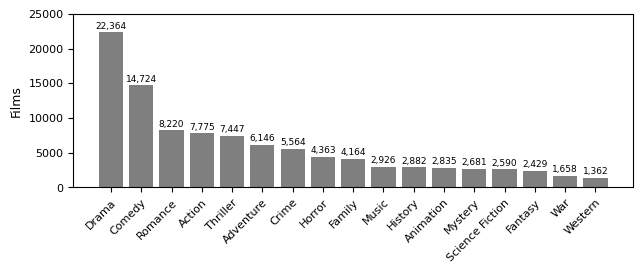

saved fig_corpus_genres


In [5]:
gf = genre_films.sort_values(ascending=False)
fig, ax = plt.subplots(figsize=S.size(1.0, 2.8))
ax.bar(gf.index, gf.values, color=GRAY)
for i, v in enumerate(gf.values):
    ax.text(i, v + 250, f'{v:,}', ha='center', va='bottom', fontsize=6.5)
ax.set_ylim(0, gf.max() * 1.12); ax.set_ylabel('Films'); rotate(ax)
save(fig, 'fig_corpus_genres')

## Table: features extracted and kept

Unique (feature, grammatical type) pairs at each stage. "Before the filter" counts every pair Notebook 02 extracted; "after" counts pairs with at least ten instances (each counted once per film) and at least five films; "narrative" counts pairs the classifier kept, less the franchise blocklist.

In [6]:
ei = read_parquet(V4 / '02_elements' / 'element_index.parquet')
def kind(t): return 'named entity' if str(t).startswith('entity') else {'noun': 'noun', 'chunk': 'noun phrase', 'verb': 'verb'}[t]
before = ei[['element', 'element_type']].drop_duplicates()
before_k = before['element_type'].map(kind).value_counts()
after_k = pairs['element_type'].map(kind).value_counts()
narr_k = pairs[pairs['narrative']]['element_type'].map(kind).value_counts()
print(f'before the filter: {len(before):,} pairs')
order = ['noun', 'noun phrase', 'verb', 'named entity']
rows = [[k, f'{before_k.get(k, 0):,}', f'{after_k.get(k, 0):,}', f'{narr_k.get(k, 0):,}',
         f'{100 * narr_k.get(k, 0) / after_k.get(k, 1):.0f}\\%'] for k in order]
rows.append([r'\midrule Total', f'{len(before):,}', f'{n_pairs:,}', f'{n_narr:,}', f'{100 * n_narr / n_pairs:.1f}\\%'])
write_table('T-III-extraction', 'Features extracted, filtered and kept.', 'tab:extraction', 'lrrrr',
            ['Type', 'Extracted', 'After 10/5 filter', 'Narrative', 'Share kept'], rows,
            'Counts are unique (feature, grammatical type) pairs across the corpus. The 10/5 filter keeps pairs with at least ten '
            'instances, each counted once per film, and at least five films. Narrative pairs are those the classifier labeled as '
            'characters, settings, objects, events, themes or relationships, less a short blocklist of franchise names.')
print(pd.DataFrame(rows).to_string(index=False, header=False))

before the filter: 588,354 pairs
wrote table T-III-extraction
          noun  64,379 11,989  7,656   64\%
   noun phrase 420,949  8,069  6,752   84\%
          verb   7,825  3,499  2,864   82\%
  named entity  95,201  3,655    693   19\%
\midrule Total 588,354 27,212 17,965 66.0\%


## Table and figure: how much of a reader's features the extraction finds (Notebook 02b)

A language model read 1,500 summaries (88 or 89 per genre) and listed their settings, characters, objects, events and themes. Recall is the share of those features that the pipeline's spaCy extraction also found in the same summary, computed under three matching rules. The 02b notebook used the loosest (one string contained in the other, so that "con" matches "conspiracy"); the September 2026 audit recommended word boundaries. Recomputed here from the cached outputs.

films: 1,500  (per genre 88 to 89)
pooled recall: {'substring': 0.653, 'word_boundary': 0.534, 'exact': 0.107} | chunk precision 0.386
wrote table T-III-validation


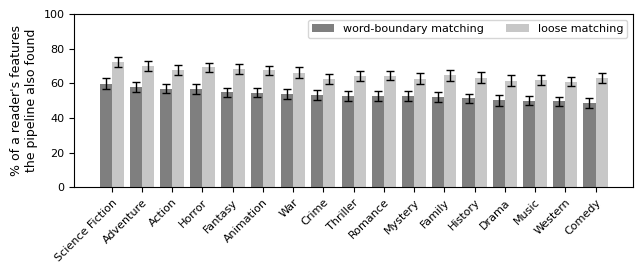

saved fig_extraction_recall
{'Science Fiction': 59.8, 'Adventure': 58.1, 'Action': 57.0, 'Horror': 56.8, 'Fantasy': 54.8, 'Animation': 54.7, 'War': 53.7, 'Crime': 53.3, 'Thriller': 52.9, 'Romance': 52.6, 'Mystery': 52.5, 'Family': 52.2, 'History': 51.3, 'Drama': 50.3, 'Music': 50.0, 'Western': 49.6, 'Comedy': 48.6}


In [7]:
llm = read_parquet(V4 / '02b_llm_validation' / 'llm_extractions.parquet')
ebf = read_parquet(V4 / '02_elements' / 'elements_by_film.parquet').set_index('union_id')
am = read_parquet(V4 / '02b_llm_validation' / 'agreement_metrics.parquet')[['union_id', 'genre', 'chunk_precision']]
def llm_set(r):
    out = set()
    for cat in ['settings', 'characters', 'objects', 'events', 'themes']:
        v = r[cat]
        if isinstance(v, str):
            try: v = json.loads(v)
            except Exception: v = []
        for e in (v if v is not None else []):
            if isinstance(e, str) and e.strip(): out.add(e.lower().strip())
    return out
rec = []
for r in llm.itertuples(index=False):
    r = r._asdict()
    if r.get('error'): continue
    L = llm_set(r)
    if not L or r['union_id'] not in ebf.index: continue
    f = ebf.loc[r['union_id']]
    Sp = {str(x).lower().strip() for col in ['nouns', 'chunks', 'verbs', 'entities'] for x in (f[col] if f[col] is not None else []) if str(x).strip()}
    pats = {s: re.compile(r'\b' + re.escape(s) + r'\b') for s in Sp}
    sub = wb = ex = 0
    for t in L:
        sub += any(s in t or t in s for s in Sp)
        wb += any(pats[s].search(t) or re.search(r'\b' + re.escape(t) + r'\b', s) for s in Sp)
        ex += t in Sp
    rec.append((r['union_id'], len(L), sub / len(L), wb / len(L), ex / len(L)))
rec = pd.DataFrame(rec, columns=['union_id', 'n_llm', 'substring', 'word_boundary', 'exact']).merge(am, on='union_id')
print(f'films: {len(rec):,}  (per genre {rec.groupby("genre").size().min()} to {rec.groupby("genre").size().max()})')
pooled = rec[['substring', 'word_boundary', 'exact']].mean()
print('pooled recall:', pooled.round(3).to_dict(), '| chunk precision', round(rec['chunk_precision'].mean(), 3))
rows = [['Films read by the language model', f'{len(rec):,}', ''],
        ['Features listed per film (mean)', f"{rec['n_llm'].mean():.1f}", ''],
        ['Recall, loose matching (one string inside the other)', f"{pooled['substring']:.3f}", 'used in 2026 drafts'],
        ['Recall, word-boundary matching', f"{pooled['word_boundary']:.3f}", 'reported'],
        ['Recall, exact matching', f"{pooled['exact']:.3f}", ''],
        ['Noun-phrase precision', f"{rec['chunk_precision'].mean():.3f}", '']]
write_table('T-III-validation', 'How much of a reader\'s features the extraction finds.', 'tab:extraction-validation', 'lrl',
            ['Quantity', 'Value', ''], rows,
            'A language model read a stratified sample of 1,500 summaries (88 or 89 per genre, seed 20260219) and listed their '
            'settings, characters, objects, events and themes. Recall is the share of those features the pipeline also extracted '
            'from the same summary, averaged over films; noun-phrase precision is the share of the pipeline\'s noun phrases the '
            'model also listed.')
g = rec.groupby('genre')[['word_boundary', 'substring']].agg(['mean', 'std', 'size'])
order_g = g[('word_boundary', 'mean')].sort_values(ascending=False).index
fig, ax = plt.subplots(figsize=S.size(1.0, 2.8))
x = np.arange(len(order_g)); w = 0.4
for off, col, k, lab in [(-w / 2, GRAY, 'word_boundary', 'word-boundary matching'), (w / 2, LIGHT, 'substring', 'loose matching')]:
    m = 100 * g.loc[order_g, (k, 'mean')]; h = 100 * 1.96 * g.loc[order_g, (k, 'std')] / np.sqrt(g.loc[order_g, (k, 'size')])
    ax.bar(x + off, m, w, color=col, yerr=h, error_kw=S.ERR, label=lab)
ax.set_xticks(x); ax.set_xticklabels(order_g); rotate(ax)
ax.set_ylim(0, 100); ax.set_ylabel("% of a reader's features\nthe pipeline also found"); ax.legend(loc='upper right', ncol=2)
save(fig, 'fig_extraction_recall')
print((100 * g.loc[order_g, ('word_boundary', 'mean')]).round(1).to_dict())

## Figure: what the narrative classifier kept

The ten categories of the classifier, counted over the 27,212 (feature, type) pairs that pass the 10/5 filter. The first six are kept as narrative; the last four are filtered out.

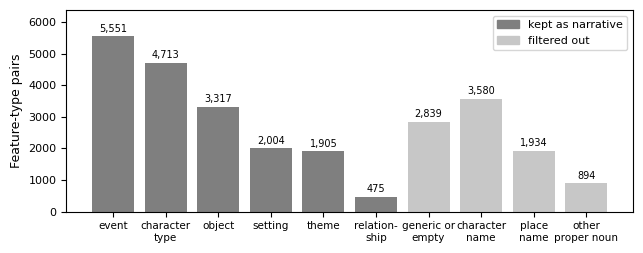

saved fig_taxonomy
element_taxonomy
event                5551
character_type       4713
object               3317
setting              2004
theme                1905
relationship          475
generic_or_empty     2839
character_name       3580
place_name           1934
proper_noun_other     894
narrative total 17965


In [8]:
NARR_CATS = ['event', 'character_type', 'object', 'setting', 'theme', 'relationship']
FILT_CATS = ['generic_or_empty', 'character_name', 'place_name', 'proper_noun_other']
NICE = {'event': 'event', 'character_type': 'character\ntype', 'object': 'object', 'setting': 'setting', 'theme': 'theme',
        'relationship': 'relation-\nship', 'generic_or_empty': 'generic or\nempty', 'character_name': 'character\nname',
        'place_name': 'place\nname', 'proper_noun_other': 'other\nproper noun'}
tx = pairs['element_taxonomy'].value_counts()
cats = NARR_CATS + FILT_CATS
fig, ax = plt.subplots(figsize=S.size(1.0, 2.6))
ax.bar(range(len(cats)), [tx.get(c, 0) for c in cats], color=[GRAY] * 6 + [LIGHT] * 4)
for i, c in enumerate(cats):
    ax.text(i, tx.get(c, 0) + 80, f'{tx.get(c, 0):,}', ha='center', va='bottom', fontsize=7)
ax.set_xticks(range(len(cats))); ax.set_xticklabels([NICE[c] for c in cats], fontsize=7.5)
ax.set_ylabel('Feature-type pairs'); ax.set_ylim(0, tx.max() * 1.15)
ax.legend(handles=[Patch(color=GRAY, label='kept as narrative'), Patch(color=LIGHT, label='filtered out')], loc='upper right')
save(fig, 'fig_taxonomy')
print(tx.reindex(cats).to_string()); print('narrative total', tx.reindex(NARR_CATS).sum())

# Part IV.A. Two numbers in the corpus

The scatter plots use the study pool: story features found in at least 20 of the genre's films (the threshold below which the split-half reliability of Part IV.B is poor).

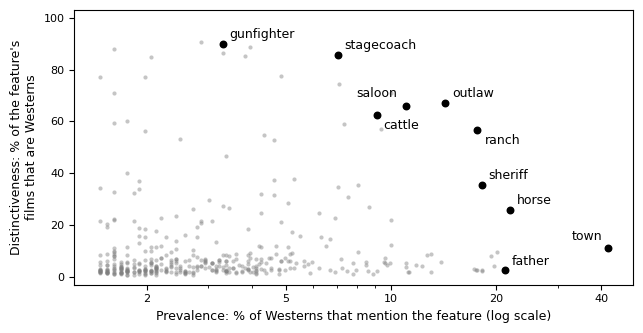

saved fig_western_dimensions
Western pool: 405 features
   element  film_count  rel_freq_in_genre  posterior_smoothed
    cattle         124              0.091               0.623
    father         288              0.211               0.026
gunfighter          45              0.033               0.900
     horse         299              0.220               0.259
    outlaw         195              0.143               0.672
     ranch         241              0.177               0.568
    saloon         150              0.110               0.661
   sheriff         248              0.182               0.355
stagecoach          96              0.070               0.857
      town         568              0.417               0.111


In [9]:
pool = pd.read_csv(V4 / '10_human_study_stimuli' / 'eligible_pool_predictors.csv')
pool = pool[pool['in_generation_analysis_set']]
w = pool[pool['genre'] == 'Western']
fig, ax = plt.subplots(figsize=S.size(1.0, 3.4))
ax.scatter(100 * w['rel_freq_in_genre'], 100 * w['posterior_smoothed'], s=9, color=GRAY, alpha=0.45, lw=0)
NAMED = {'town': (-4, 6), 'father': (5, 4), 'horse': (5, 4), 'sheriff': (5, 4), 'ranch': (5, -10), 'saloon': (-6, 6),
         'stagecoach': (5, 4), 'gunfighter': (5, 4), 'outlaw': (5, 4), 'cattle': (5, -10)}
HA = {'saloon': 'right', 'town': 'right'}
for e, off in NAMED.items():
    r = w[w['element'] == e]
    if r.empty: continue
    r = r.iloc[0]
    ax.scatter(100 * r['rel_freq_in_genre'], 100 * r['posterior_smoothed'], s=22, color=S.INK, zorder=3)
    ax.annotate(e, (100 * r['rel_freq_in_genre'], 100 * r['posterior_smoothed']), xytext=off, textcoords='offset points', ha=HA.get(e, 'left'))
ax.set_xscale('log'); ax.set_xticks([2, 5, 10, 20, 40]); ax.set_xticklabels(['2', '5', '10', '20', '40'])
ax.set_xlabel('Prevalence: % of Westerns that mention the feature (log scale)')
ax.set_ylabel("Distinctiveness: % of the feature's\nfilms that are Westerns"); ax.set_ylim(-3, 103)
save(fig, 'fig_western_dimensions')
print(f'Western pool: {len(w)} features')
print(w[w['element'].isin(NAMED)][['element', 'film_count', 'rel_freq_in_genre', 'posterior_smoothed']].round(3).to_string(index=False))

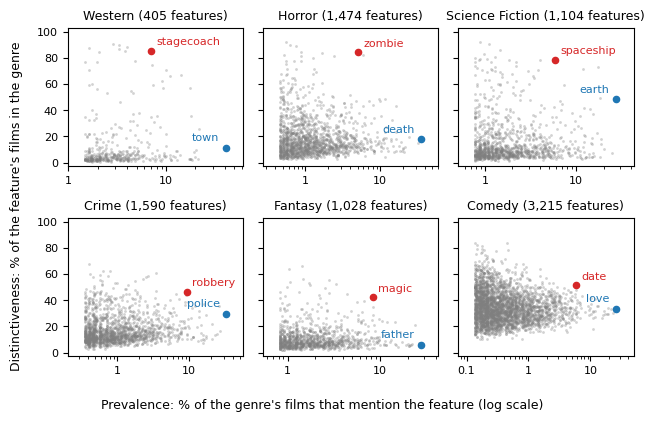

saved fig_six_genres


In [10]:
fig, axes = plt.subplots(2, 3, figsize=S.size(1.0, 4.2), sharey=True)
pair_rows = []
for ax, g in zip(axes.ravel(), SIX):
    d = pool[pool['genre'] == g]
    ax.scatter(100 * d['rel_freq_in_genre'], 100 * d['posterior_smoothed'], s=4, color=GRAY, alpha=0.35, lw=0)
    common = d.nlargest(1, 'rel_freq_in_genre').iloc[0]
    char = d[d['rel_freq_in_genre'] >= 0.05].nlargest(1, 'posterior_smoothed').iloc[0]
    pair_rows += [(g, 'most prevalent', common), (g, 'most distinctive', char)]
    for r, col, off, ha in [(common, BLUE, (-5, 5), 'right'), (char, RED, (4, 4), 'left')]:
        ax.scatter(100 * r['rel_freq_in_genre'], 100 * r['posterior_smoothed'], s=20, color=col, zorder=3)
        ax.annotate(r['element'], (100 * r['rel_freq_in_genre'], 100 * r['posterior_smoothed']), xytext=off,
                    textcoords='offset points', ha=ha, color=col, fontsize=8)
    ax.set_xscale('log'); ax.set_ylim(-3, 103); ax.margins(x=0.12)
    ax.xaxis.set_major_formatter(plt.FuncFormatter(lambda v, _: f'{v:g}'))
    ax.set_title(f'{g} ({len(d):,} features)')
fig.supxlabel("Prevalence: % of the genre's films that mention the feature (log scale)", fontsize=S.FONT_SIZE)
fig.supylabel("Distinctiveness: % of the feature's films in the genre", fontsize=S.FONT_SIZE)
save(fig, 'fig_six_genres')

## Figure: the same split in six genres

For each genre, the feature with the highest prevalence and the feature with the highest distinctiveness among those in at least 5% of the genre's films (the features named in the six-genre scatter). Bars are percentages with 95% Wilson intervals from the film counts.

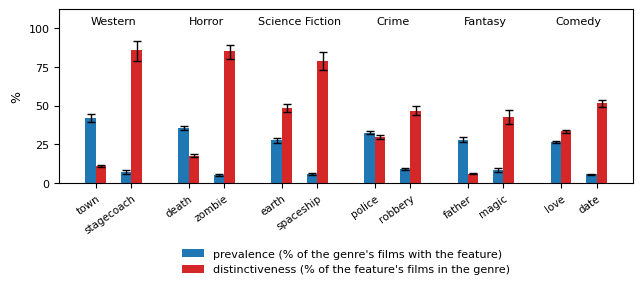

saved fig_six_genre_pairs
          genre             kind    element  film_count  prevalence  distinctiveness
        Western   most prevalent       town         568       0.417            0.111
        Western most distinctive stagecoach          96       0.070            0.857
         Horror   most prevalent      death        1555       0.356            0.178
         Horror most distinctive     zombie         222       0.051            0.847
Science Fiction   most prevalent      earth         716       0.276            0.484
Science Fiction most distinctive  spaceship         153       0.059            0.789
          Crime   most prevalent     police        1815       0.326            0.297
          Crime most distinctive    robbery         512       0.092            0.467
        Fantasy   most prevalent     father         682       0.281            0.061
        Fantasy most distinctive      magic         203       0.084            0.425
         Comedy   most prevalent       

In [11]:
pr = pd.DataFrame([(g, k, r['element'], r['element_type'], r['film_count'], r['rel_freq_in_genre'], r['posterior_smoothed'])
                   for g, k, r in pair_rows], columns=['genre', 'kind', 'element', 'element_type', 'film_count', 'prevalence', 'distinctiveness'])
pr = pr.merge(sl[['genre', 'element', 'element_type', 'total_film_count']], on=['genre', 'element', 'element_type'], how='left')
pr['films_in_genre'] = pr['genre'].map(genre_films)
p_lo, p_hi = wilson(pr['film_count'], pr['films_in_genre']); d_lo, d_hi = wilson(pr['film_count'], pr['total_film_count'])
fig, ax = plt.subplots(figsize=S.size(1.0, 3.2))
x = np.arange(len(pr)) * 1.3 + np.repeat(np.arange(len(SIX)), 2) * 0.8
wd = 0.38
pv, dv = 100 * pr['prevalence'], 100 * pr['distinctiveness']
ax.bar(x - wd / 2, pv, wd, color=BLUE, label="prevalence (% of the genre's films with the feature)",
       yerr=[np.clip(pv - 100 * p_lo, 0, None), np.clip(100 * p_hi - pv, 0, None)], error_kw=S.ERR)
ax.bar(x + wd / 2, dv, wd, color=RED, label="distinctiveness (% of the feature's films in the genre)",
       yerr=[np.clip(dv - 100 * d_lo, 0, None), np.clip(100 * d_hi - dv, 0, None)], error_kw=S.ERR)
ax.set_xticks(x); ax.set_xticklabels(pr['element'], fontsize=7.5); rotate(ax, 35)
for i, g in enumerate(SIX):
    ax.text(x[2 * i:2 * i + 2].mean(), 101, g, ha='center', va='bottom', fontsize=8)
ax.set_ylim(0, 112); ax.set_yticks([0, 25, 50, 75, 100]); ax.set_ylabel('%')
ax.legend(loc='upper center', bbox_to_anchor=(0.5, -0.32), ncol=1, frameon=False)
save(fig, 'fig_six_genre_pairs')
print(pr[['genre', 'kind', 'element', 'film_count', 'prevalence', 'distinctiveness']].round(3).to_string(index=False))

## Figure: how the six scores rank features

Mean within-genre Spearman correlation over the 17 genres among story features (Notebook 14).

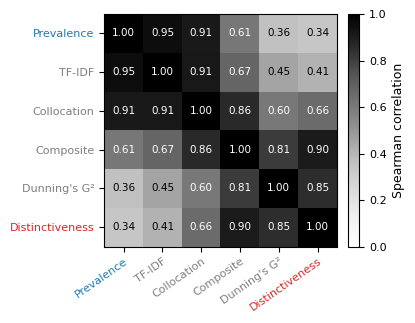

saved fig_score_correlation
                 prevalence  tfidf  collocation  composite    g2  distinctiveness
prevalence             1.00   0.95         0.91       0.61  0.36             0.34
tfidf                  0.95   1.00         0.91       0.67  0.45             0.41
collocation            0.91   0.91         1.00       0.86  0.60             0.66
composite              0.61   0.67         0.86       1.00  0.81             0.90
g2                     0.36   0.45         0.60       0.81  1.00             0.85
distinctiveness        0.34   0.41         0.66       0.90  0.85             1.00


In [12]:
corr = read_parquet(V4 / '14_dimension_checks' / 'measure_correlation.parquet')
order = ['prevalence', 'tfidf', 'collocation', 'composite', 'g2', 'distinctiveness']
m = corr.loc[order, order].values
fig, ax = plt.subplots(figsize=S.size(0.62, 3.3))
im = ax.imshow(m, vmin=0, vmax=1, cmap=S.CMAP)
for i in range(len(order)):
    for j in range(len(order)):
        ax.text(j, i, f'{m[i, j]:.2f}', ha='center', va='center', fontsize=7.5, color='white' if m[i, j] > 0.6 else S.INK)
ax.set_xticks(range(len(order))); ax.set_xticklabels([LAB[o] for o in order]); rotate(ax, 35)
ax.set_yticks(range(len(order))); ax.set_yticklabels([LAB[o] for o in order])
for t in ax.get_xticklabels() + ax.get_yticklabels():
    t.set_color(color_of([k for k in order if LAB[k] == t.get_text()][0]))
fig.colorbar(im, ax=ax, fraction=0.046, pad=0.04, label='Spearman correlation')
save(fig, 'fig_score_correlation')
print(corr.loc[order, order].round(2).to_string())

## Figure: whose top 50 is the composite's top 50

For each genre, the number of the composite's 50 highest story features that are also among the 50 highest on each other score; bars are means over 17 genres with 95% t intervals, dots are genres.

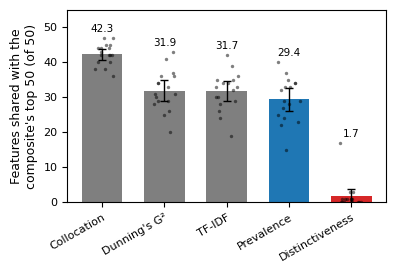

saved fig_top50_overlap
composite_and_collocation         42.3
composite_and_g2                  31.9
composite_and_tfidf               31.7
composite_and_prevalence          29.4
composite_and_distinctiveness      1.7
prevalence_and_distinctiveness     0.0


In [13]:
ov = read_parquet(V4 / '14_dimension_checks' / 'top50_overlap.parquet')
keys = ['collocation', 'g2', 'tfidf', 'prevalence', 'distinctiveness']
fig, ax = plt.subplots(figsize=S.size(0.62, 2.8))
jit = np.random.default_rng(SEED)
for i, k in enumerate(keys):
    v = ov[f'composite_and_{k}'].values; lo, hi = mean_ci(v)
    ax.bar(i, v.mean(), 0.65, color=color_of(k))
    ax.errorbar(i, v.mean(), yerr=[[v.mean() - lo], [hi - v.mean()]], fmt='none', **S.ERR)
    ax.scatter(i + jit.uniform(-0.18, 0.18, len(v)), v, s=6, color=S.INK, alpha=0.5, zorder=3, lw=0)
    ax.text(i, max(hi, v.max()) + 1.2, f'{v.mean():.1f}', ha='center', va='bottom', fontsize=7.5)
ax.set_xticks(range(len(keys))); ax.set_xticklabels([LAB[k] for k in keys]); rotate(ax, 30)
ax.set_ylim(0, 55); ax.set_ylabel("Features shared with the\ncomposite's top 50 (of 50)")
save(fig, 'fig_top50_overlap')
print(ov[[f'composite_and_{k}' for k in keys] + ['prevalence_and_distinctiveness']].mean().round(1).to_string())

## Tables: the top features on each measure

Story features found in at least 20 of the genre's films, ranked within the genre by prevalence and, separately, by distinctiveness (smoothed). A feature appearing under two grammatical types is listed once, and so is a word the parser produced in two spellings that differ by a plural or lemma ending. The six study genres go in the text; all seventeen go in the supplement.

In [14]:
rk = sl[sl['narrative'] & (sl['film_count'] >= 20)].copy()
def top(g, col, k):
    # Ranked list, one entry per surface form. A form that is the same word as one already listed with up to two letters
    # added or removed (the parser's plural and lemma variants, e.g. apaches / apach) is listed once, under the higher rank.
    d = rk[rk['genre'] == g].sort_values(col, ascending=False).drop_duplicates('element')
    out = []
    for e in d['element']:
        if any((e.startswith(o) or o.startswith(e)) and abs(len(e) - len(o)) <= 2 for o in out):
            continue
        out.append(e)
        if len(out) == k: break
    return out
rows = [[g, ', '.join(map(tex_escape, top(g, 'rel_freq_in_genre', 5))), ', '.join(map(tex_escape, top(g, 'posterior_smoothed', 5)))] for g in SIX]
write_table('T-IV-top5', 'The five highest features on each measure, six genres.', 'tab:top5', 'lp{2.45in}p{2.45in}',
            ['Genre', 'Highest prevalence', 'Highest distinctiveness'], rows,
            'Story features found in at least 20 of the genre\'s films, ranked within the genre. Prevalence is the share of the '
            'genre\'s films that mention the feature; distinctiveness is the share of the films mentioning it that are in the genre '
            '(smoothed).', size=r'\footnotesize')
for r in rows: print(r[0], '|', r[1], '|', r[2])
# Supplement: all seventeen genres, top ten each (longtable; the supplement loads longtable)
lines = []
for g in GEN:
    lines.append(f"{tex_escape(g)} & {', '.join(map(tex_escape, top(g, 'rel_freq_in_genre', 10)))} & "
                 f"{', '.join(map(tex_escape, top(g, 'posterior_smoothed', 10)))} \\\\")
sup = (r'\begin{longtable}{p{0.95in}p{2.45in}p{2.45in}}' '\n'
       r'\caption{The ten highest features on each measure, all seventeen genres.}\label{tab:top10-two-measures}\\' '\n'
       r'\toprule Genre & Highest prevalence & Highest distinctiveness \\ \midrule \endfirsthead' '\n'
       r'\toprule Genre & Highest prevalence & Highest distinctiveness \\ \midrule \endhead' '\n'
       r'\bottomrule \endfoot' '\n' + '\n'.join(lines).replace('\\\\\n', '\\\\[3pt]\n') + '\n' r'\end{longtable}' '\n'
       r'{\footnotesize\emph{Note:} Story features found in at least 20 of the genre’s films.\par}' '\n')
(TAB / 'T-App-A_top10_two_measures.tex').write_text('{\\footnotesize\n' + sup + '}\n')
print('wrote table T-App-A_top10_two_measures')

wrote table T-IV-top5
Western | kill, town, shoot, return, arrive | apaches, gunfighter, sioux, rustler, cattle rustler
Horror | kill, discover, death, escape, die | vampirism, vampire hunter, paranormal activity, zombie, haunting
Science Fiction | kill, discover, escape, return, destroy | lifeform, starship, home planet, airlock, space station
Crime | kill, police, shoot, death, discover | crime lord, launder, precinct, triad, heist
Fantasy | return, kill, fall, discover, escape | sorceress, troll, magical power, fairy, wand
Comedy | fall, love, return, run, discover | trampoline, makeover, bridesmaid, bachelor party, car salesman
wrote table T-App-A_top10_two_measures


# Part IV.B. Checks on the measures

## Figure: the meaning check, by score

Cohen's d for how much closer in meaning to the genre the top 50 features on each score are than the other story features (cosine similarity to the genre centroid in voyage-4-large space; Notebook 14, Part A3). Bars are means over 17 genres with 95% t intervals; dots are genres.

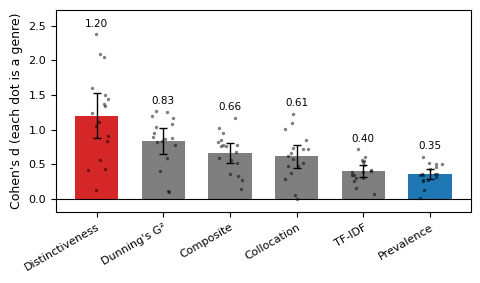

saved fig_meaning_by_score
measure
distinctiveness    1.20
g2                 0.83
composite          0.66
collocation        0.61
tfidf              0.40
prevalence         0.35


In [15]:
meaning = read_parquet(V4 / '14_dimension_checks' / 'meaning_by_measure.parquet')
sorder = ['distinctiveness', 'g2', 'composite', 'collocation', 'tfidf', 'prevalence']
piv = meaning.pivot(index='genre', columns='measure', values='cohens_d')[sorder]
fig, ax = plt.subplots(figsize=S.size(0.75, 2.9))
jit = np.random.default_rng(SEED)
for i, k in enumerate(sorder):
    v = piv[k].values; lo, hi = mean_ci(v)
    ax.bar(i, v.mean(), 0.65, color=color_of(k))
    ax.errorbar(i, v.mean(), yerr=[[v.mean() - lo], [hi - v.mean()]], fmt='none', **S.ERR)
    ax.scatter(i + jit.uniform(-0.18, 0.18, len(v)), v, s=6, color=S.INK, alpha=0.5, zorder=3, lw=0)
    ax.text(i, v.max() + 0.08, f'{v.mean():.2f}', ha='center', va='bottom', fontsize=7.5)
ax.axhline(0, color=S.INK, lw=0.8)
ax.set_xticks(range(len(sorder))); ax.set_xticklabels([LAB[k] for k in sorder]); rotate(ax, 30)
ax.set_ylabel("Cohen's d (each dot is a genre)"); ax.set_ylim(-0.2, piv.values.max() + 0.35)
save(fig, 'fig_meaning_by_score')
print(piv.mean().round(2).to_string())

## Figure: the meaning check genre by genre (supplement)

The same Cohen's d for prevalence and for distinctiveness in each genre, with a 95% interval from the standard error of d (50 top features against the rest). This replaces the May draft's "Arm 1" figure, which used the composite's top 50 against a random 50.

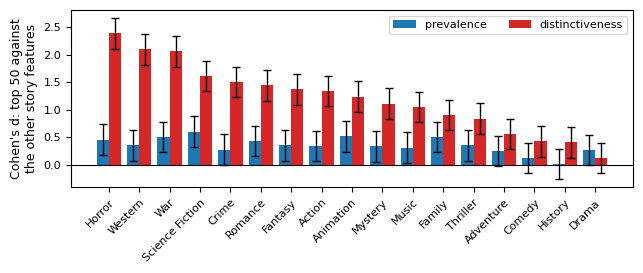

saved fig_meaning_by_genre


In [16]:
nn = sl[sl['narrative']].groupby('genre').size()
def se_d(d, n1, n2): return np.sqrt((n1 + n2) / (n1 * n2) + d ** 2 / (2 * (n1 + n2)))
gorder = piv['distinctiveness'].sort_values(ascending=False).index
fig, ax = plt.subplots(figsize=S.size(1.0, 2.8))
x = np.arange(len(gorder)); wd = 0.4
for off, k in [(-wd / 2, 'prevalence'), (wd / 2, 'distinctiveness')]:
    d = piv.loc[gorder, k].values; se = se_d(d, 50, nn.loc[gorder].values - 50)
    ax.bar(x + off, d, wd, color=color_of(k), yerr=1.96 * se, error_kw=S.ERR, label=k)
ax.axhline(0, color=S.INK, lw=0.8)
ax.set_xticks(x); ax.set_xticklabels(gorder); rotate(ax)
ax.set_ylabel("Cohen's d: top 50 against\nthe other story features"); ax.legend(loc='upper right', ncol=2)
save(fig, 'fig_meaning_by_genre')

## Figure: what the narrative classifier kept, genre by genre

For each genre, the 50 highest story features against the 50 highest features the classifier filtered out, compared by closeness in meaning to the genre (Cohen's d with a 95% interval; Notebook 05). Light gray marks genres whose interval crosses zero. This is the May draft's "Arm 2", which is a check on the narrative filter, not on the measures.

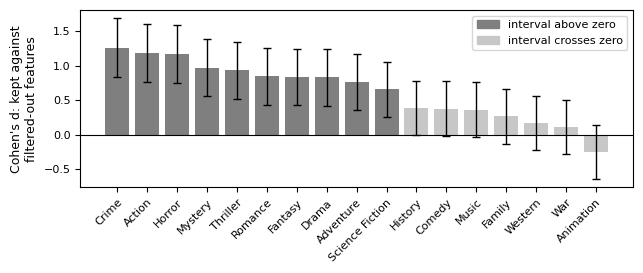

saved fig_classifier_check
mean d 0.64; d > 0 in 16 of 17; reliable in 10
          genre  cohens_d
          Crime      1.26
         Action      1.18
         Horror      1.17
        Mystery      0.97
       Thriller      0.93
        Romance      0.84
        Fantasy      0.83
          Drama      0.83
      Adventure      0.76
Science Fiction      0.66
        History      0.38
         Comedy      0.37
          Music      0.36
         Family      0.26
        Western      0.17
            War      0.11
      Animation     -0.26


In [17]:
fv = read_parquet(V4 / '05_embeddings' / 'filter_validation.parquet').sort_values('cohens_d', ascending=False)
se = se_d(fv['cohens_d'].values, fv['n_narr'].values, fv['n_filt'].values)
reliable = (fv['cohens_d'].values - 1.96 * se) > 0
fig, ax = plt.subplots(figsize=S.size(1.0, 2.8))
ax.bar(fv['genre'], fv['cohens_d'], color=np.where(reliable, GRAY, LIGHT), yerr=1.96 * se, error_kw=S.ERR)
ax.axhline(0, color=S.INK, lw=0.8); rotate(ax)
ax.set_ylabel("Cohen's d: kept against\nfiltered-out features")
ax.legend(handles=[Patch(color=GRAY, label='interval above zero'), Patch(color=LIGHT, label='interval crosses zero')], loc='upper right')
save(fig, 'fig_classifier_check')
print(f"mean d {fv['cohens_d'].mean():.2f}; d > 0 in {int((fv['cohens_d'] > 0).sum())} of {len(fv)}; reliable in {int(reliable.sum())}")
print(fv[['genre', 'cohens_d']].round(2).to_string(index=False))

## Figures: held-out prediction (Notebook 14, Part B)

The films are split in half at random; both measures are computed on one half and tested on the other. Left: knowing a film's genre, rank the features and ask whether the film's own features come out on top. Right: knowing a film's features, ask whether films of the genre score higher than films outside it. AUC 0.5 is guessing.

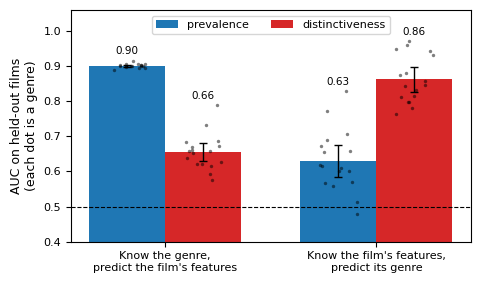

saved fig_heldout_prediction
Know the genre, predict the film's features {'auc_prevalence': 0.901, 'auc_distinctiveness': 0.656}
Know the film's features, predict its genre {'auc_prevalence': 0.63, 'auc_distinctiveness': 0.862}
overall frequency, genre -> content: 0.894
no narrative filter (all features): genre -> content prevalence 0.908 | content -> genre distinctiveness 0.868


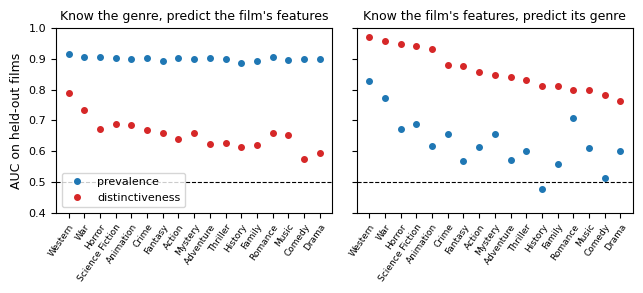

saved fig_heldout_by_genre
genres showing the double dissociation: 17 of 17


In [18]:
hc = read_parquet(V4 / '14_dimension_checks' / 'heldout_content.parquet')
hg = read_parquet(V4 / '14_dimension_checks' / 'heldout_genre.parquet')
hc_n, hg_n = hc[hc['set'] == 'narrative'].set_index('genre'), hg[hg['set'] == 'narrative'].set_index('genre')
tasks = [("Know the genre,\npredict the film's features", hc_n), ("Know the film's features,\npredict its genre", hg_n)]
fig, ax = plt.subplots(figsize=S.size(0.75, 2.9))
wd = 0.36; jit = np.random.default_rng(SEED)
for t, (name, tab) in enumerate(tasks):
    for off, k in [(-wd / 2, 'prevalence'), (wd / 2, 'distinctiveness')]:
        v = tab[f'auc_{k}'].values; lo, hi = mean_ci(v)
        ax.bar(t + off, v.mean(), wd, color=color_of(k), label=k if t == 0 else None)
        ax.errorbar(t + off, v.mean(), yerr=[[v.mean() - lo], [hi - v.mean()]], fmt='none', **S.ERR)
        ax.scatter(t + off + jit.uniform(-0.09, 0.09, len(v)), v, s=6, color=S.INK, alpha=0.5, zorder=3, lw=0)
        ax.text(t + off, v.max() + 0.012, f'{v.mean():.2f}', ha='center', va='bottom', fontsize=7.5)
ax.axhline(0.5, color=S.INK, ls='--', lw=0.8)
ax.set_xticks([0, 1]); ax.set_xticklabels([n for n, _ in tasks]); ax.set_ylim(0.4, 1.06)
ax.set_ylabel('AUC on held-out films\n(each dot is a genre)'); ax.legend(loc='upper center', ncol=2)
save(fig, 'fig_heldout_prediction')
for name, tab in tasks:
    print(name.replace('\n', ' '), tab[['auc_prevalence', 'auc_distinctiveness']].mean().round(3).to_dict())
print('overall frequency, genre -> content:', round(hc_n['auc_overall_frequency'].mean(), 3))
print('no narrative filter (all features): genre -> content prevalence', round(hc[hc['set'] == 'all_elements']['auc_prevalence'].mean(), 3),
      '| content -> genre distinctiveness', round(hg[hg['set'] == 'all_elements']['auc_distinctiveness'].mean(), 3))

gorder = hg_n['auc_distinctiveness'].sort_values(ascending=False).index
fig, axes = plt.subplots(1, 2, figsize=S.size(1.0, 3.0), sharey=True)
xx = np.arange(len(gorder))
for ax, (name, tab) in zip(axes, tasks):
    for k in ['prevalence', 'distinctiveness']:
        ax.plot(xx, tab.loc[gorder, f'auc_{k}'], 'o', ms=4, color=color_of(k), label=k)
    ax.axhline(0.5, color=S.INK, ls='--', lw=0.8); ax.set_ylim(0.4, 1.0); ax.set_title(name.replace('\n', ' '))
    ax.set_xticks(xx); ax.set_xticklabels(gorder, fontsize=6.5); rotate(ax, 55)
axes[0].set_ylabel('AUC on held-out films'); axes[0].legend(loc='lower left')
save(fig, 'fig_heldout_by_genre')
both = int(((hc_n['auc_prevalence'] > hc_n['auc_distinctiveness']) & (hg_n.loc[hc_n.index, 'auc_distinctiveness'] > hg_n.loc[hc_n.index, 'auc_prevalence'])).sum())
print(f'genres showing the double dissociation: {both} of {len(hc_n)}')

## Figure: how stable each number is (split-half reliability)

Spearman agreement between the two halves of the corpus, by how many of the genre's films mention the feature; bars are means over 17 genres with 95% t intervals (Notebook 14, Part B3).

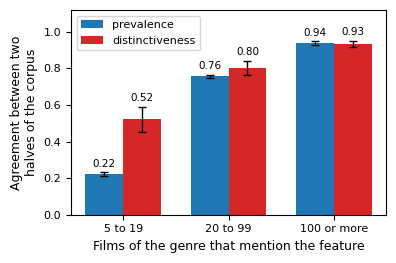

saved fig_split_half_reliability
films_in_genre  n_cells  prevalence  distinctiveness
       5 to 19    73532        0.22             0.52
      20 to 99    32058        0.76             0.80
   100 or more    10917        0.94             0.93


In [19]:
rel = read_parquet(V4 / '14_dimension_checks' / 'split_half_reliability.parquet')
fig, ax = plt.subplots(figsize=S.size(0.62, 2.7))
x = np.arange(len(rel)); wd = 0.36
half = lambda sd: stats.t.ppf(0.975, rel['n_genres'] - 1) * sd / np.sqrt(rel['n_genres'])
for off, k in [(-wd / 2, 'prevalence'), (wd / 2, 'distinctiveness')]:
    h = half(rel[f'{k}_sd'])
    ax.bar(x + off, rel[k], wd, color=color_of(k), yerr=h, error_kw=S.ERR, label=k)
    for xi, v, hh in zip(x + off, rel[k], h): ax.text(xi, v + hh + 0.02, f'{v:.2f}', ha='center', va='bottom', fontsize=7.5)
ax.set_xticks(x); ax.set_xticklabels(rel['films_in_genre']); ax.set_ylim(0, 1.12)
ax.set_xlabel("Films of the genre that mention the feature"); ax.set_ylabel('Agreement between two\nhalves of the corpus')
ax.legend(loc='upper left')
save(fig, 'fig_split_half_reliability')
print(rel[['films_in_genre', 'n_cells', 'prevalence', 'distinctiveness']].round(2).to_string(index=False))

## Figures: the language-model check, re-described on the two measures

Notebook 04 scored every summary's predictability with a language model (mean surprisal per token, Qwen2.5-7B). The May draft correlated it with each film's mean composite score, controlling for length. Here the same partial correlation is computed for the film's mean prevalence percentile and mean distinctiveness percentile (each feature ranked within its genre and grammatical type, averaged over the film's story feature-genre cells), alongside the composite version. Length is the log of the summary's word count. A negative r means more stock-heavy films are more predictable. Per genre, the films of that genre.

films: 45,953
prevalence       raw r -0.061   partial r -0.154
distinctiveness  raw r +0.006   partial r -0.064
composite        raw r +0.003   partial r -0.164


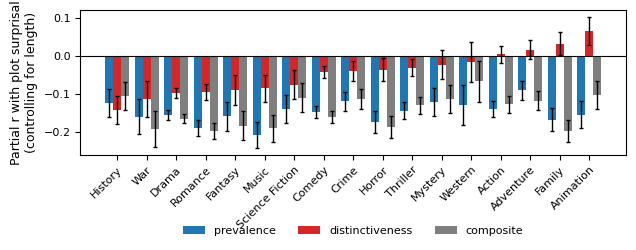

saved fig_surprisal_by_genre
                     n  prevalence  distinctiveness  composite
genre                                                         
History           2882      -0.123           -0.142     -0.104
War               1658      -0.159           -0.113     -0.192
Drama            22363      -0.156           -0.097     -0.164
Romance           8219      -0.189           -0.094     -0.196
Fantasy           2429      -0.159           -0.089     -0.182
Music             2926      -0.207           -0.085     -0.190
Science Fiction   2590      -0.139           -0.075     -0.109
Comedy           14720      -0.147           -0.042     -0.161
Crime             5564      -0.119           -0.039     -0.112
Horror            4363      -0.174           -0.036     -0.187
Thriller          7447      -0.144           -0.030     -0.130
Mystery           2681      -0.121           -0.023     -0.112
Western           1362      -0.129           -0.015     -0.067
Action            7774    

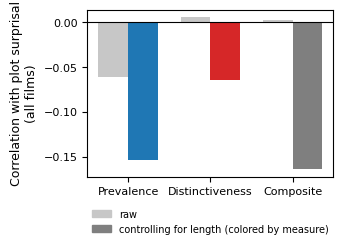

saved fig_surprisal_length
length correlations: {'prevalence': -0.133, 'distinctiveness': -0.115, 'composite': -0.264} surprisal-length -0.522


In [20]:
nc = sl[sl['narrative']][['element', 'element_type', 'genre', 'rel_freq_in_genre', 'posterior_smoothed', 'ensemble']].copy()
for k, c in [('p_prev', 'rel_freq_in_genre'), ('p_dist', 'posterior_smoothed')]:
    nc[k] = nc.groupby(['genre', 'element_type'])[c].rank(pct=True)
fg = U[['union_id', 'genres_canonical']].explode('genres_canonical').rename(columns={'genres_canonical': 'genre'}).dropna()
el = ei.drop_duplicates(['union_id', 'element', 'element_type'])
cells_f = el.merge(fg, on='union_id').merge(nc, on=['element', 'element_type', 'genre'])
pf = cells_f.groupby('union_id')[['p_prev', 'p_dist', 'ensemble']].mean()
sp = read_parquet(V4 / '04_surprisal' / 'per_film_surprisal.parquet').set_index('union_id')
D = pf.join(sp['mean_surprisal'], how='inner').join(U.set_index('union_id')['word_count'])
D = D[D['word_count'] > 0]; D['loglen'] = np.log(D['word_count'])
def partial_r(d, a, b='mean_surprisal', z='loglen'):
    X = np.c_[np.ones(len(d)), d[z].values]
    ra = d[a].values - X @ np.linalg.lstsq(X, d[a].values, rcond=None)[0]
    rb = d[b].values - X @ np.linalg.lstsq(X, d[b].values, rcond=None)[0]
    return np.corrcoef(ra, rb)[0, 1]
MEAS = [('p_prev', 'prevalence'), ('p_dist', 'distinctiveness'), ('ensemble', 'composite')]
print(f'films: {len(D):,}')
corp = {lab: (np.corrcoef(D[c], D['mean_surprisal'])[0, 1], partial_r(D, c)) for c, lab in MEAS}
for lab, (r0, r1) in corp.items(): print(f'{lab:16s} raw r {r0:+.3f}   partial r {r1:+.3f}')
fgi = fg.set_index('union_id')['genre']
rows_pg = []
for g in GEN:
    ids = fgi[fgi == g].index.intersection(D.index)
    d = D.loc[ids]
    rows_pg.append([g, len(d)] + [partial_r(d, c) for c, _ in MEAS])
pg = pd.DataFrame(rows_pg, columns=['genre', 'n'] + [lab for _, lab in MEAS]).set_index('genre')
pg = pg.sort_values('distinctiveness')
fig, ax = plt.subplots(figsize=S.size(1.0, 2.9))
x = np.arange(len(pg)); wd = 0.27
for off, lab in [(-wd, 'prevalence'), (0, 'distinctiveness'), (wd, 'composite')]:
    se = (1 - pg[lab] ** 2) / np.sqrt(pg['n'] - 3)        # approximate standard error of r
    ax.bar(x + off, pg[lab], wd, color=color_of(lab), yerr=1.96 * se, error_kw={**S.ERR, 'capsize': 1.5}, label=lab)
ax.axhline(0, color=S.INK, lw=0.8)
ax.set_xticks(x); ax.set_xticklabels(pg.index); rotate(ax)
ax.set_ylabel('Partial r with plot surprisal\n(controlling for length)')
ax.legend(loc='upper center', bbox_to_anchor=(0.5, -0.42), ncol=3, frameon=False)
save(fig, 'fig_surprisal_by_genre')
print(pg.round(3).to_string())

fig, ax = plt.subplots(figsize=S.size(0.55, 2.6))
x = np.arange(3); wd = 0.36
ax.bar(x - wd / 2, [corp[l][0] for _, l in MEAS], wd, color=LIGHT, label='raw')
ax.bar(x + wd / 2, [corp[l][1] for _, l in MEAS], wd, color=[color_of(l) for _, l in MEAS], label='controlling for length')
ax.axhline(0, color=S.INK, lw=0.8)
ax.set_xticks(x); ax.set_xticklabels([LAB[l] for _, l in MEAS]); ax.set_ylabel('Correlation with plot surprisal\n(all films)')
ax.legend(handles=[Patch(color=LIGHT, label='raw'), Patch(color=GRAY, label='controlling for length (colored by measure)')],
          loc='upper center', bbox_to_anchor=(0.5, -0.14), ncol=1, frameon=False, fontsize=7)
save(fig, 'fig_surprisal_length')
print('length correlations:', {lab: round(np.corrcoef(D[c], D['loglen'])[0, 1], 3) for c, lab in MEAS},
      'surprisal-length', round(np.corrcoef(D['mean_surprisal'], D['loglen'])[0, 1], 3))

# Part IV.C. The court record

## Figure: where court-named features fall on each measure

The 312 narrative court-named features matched in the court-named genre (Notebook 07b), placed by their within-genre percentile (within grammatical type) on prevalence and on distinctiveness. If courts named features at random, each bar would hold about 10%.

median percentile: {'p_prevalence': 0.931, 'p_distinctiveness': 0.698, 'p_composite': 0.935} | exact matches: {'p_prevalence': 0.873, 'p_distinctiveness': 0.763}


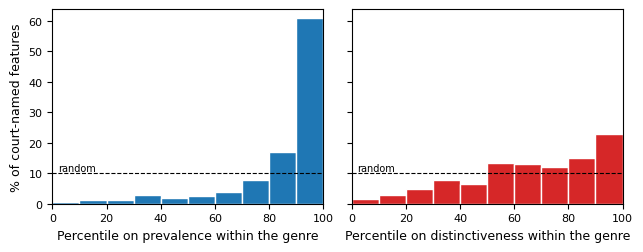

saved fig_courts_percentiles
share in top tenth: {'prevalence': 0.609, 'distinctiveness': 0.228}


In [21]:
stk = sl.copy()
for n_, c in [('prevalence', 'rel_freq_in_genre'), ('distinctiveness', 'posterior_smoothed'), ('composite', 'ensemble')]:
    stk[f'p_{n_}'] = stk.groupby(['genre', 'element_type'])[c].rank(pct=True)
best = stk.sort_values('ensemble').groupby(['element', 'genre']).tail(1).set_index(['element', 'genre'])
M = read_parquet(V4 / '07b_court_validation' / 'matched_judicial_elements.parquet')
M = M[M['is_narrative'] & M['pct'].notna()]
J = M.join(best[['p_prevalence', 'p_distinctiveness', 'p_composite']], on=['match_element', 'gen'])
assert len(J) == 312, len(J)
print('median percentile:', J[['p_prevalence', 'p_distinctiveness', 'p_composite']].median().round(3).to_dict(),
      '| exact matches:', J[J['match_method'] == 'exact'][['p_prevalence', 'p_distinctiveness']].median().round(3).to_dict())
fig, axes = plt.subplots(1, 2, figsize=S.size(1.0, 2.6), sharey=True)
bins = np.linspace(0, 100, 11)
for ax, k in zip(axes, ['prevalence', 'distinctiveness']):
    ax.hist(100 * J[f'p_{k}'], bins=bins, color=color_of(k), edgecolor='white', weights=np.full(len(J), 100 / len(J)))
    ax.axhline(10, color=S.INK, ls='--', lw=0.8)
    ax.set_xlabel(f"Percentile on {k} within the genre"); ax.set_xlim(0, 100)
    ax.text(2, 10.8, 'random', fontsize=7)
axes[0].set_ylabel('% of court-named features')
save(fig, 'fig_courts_percentiles')
print('share in top tenth:', {k: round(float((J[f'p_{k}'] >= 0.9).mean()), 3) for k in ['prevalence', 'distinctiveness']})

## Figure: is the feature specific to the court's genre?

For each case, the average position of the court-named genre among the feature's genres (0 = lowest, 1 = highest), on each measure (Notebook 07b, baseline A). Chance is 0.5.

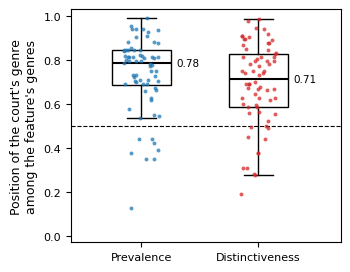

saved fig_court_genre_rank
                         measure  n_cases  median_case  cases_above  top_genre_share  top_genre_chance
                      prevalence     68.0        0.783         60.0            0.269             0.064
                 distinctiveness     68.0        0.714         56.0            0.224             0.064
                        ensemble     68.0        0.750         58.0            0.266             0.064
distinctiveness_minus_prevalence     68.0       -0.031         16.0              NaN               NaN


In [22]:
bc = read_parquet(V4 / '07b_court_validation' / 'dimension_baselines_by_case.parquet')
r_ = bc[(bc['baseline'] == 'court_genre_rank') & (bc['subset'] == 'narrative_in_genre')]
vals = {k: r_[r_['measure'] == k]['value'].values for k in ['prevalence', 'distinctiveness']}
fig, ax = plt.subplots(figsize=S.size(0.55, 2.8))
jit = np.random.default_rng(SEED)
for pos, k in enumerate(['prevalence', 'distinctiveness']):
    v = vals[k]
    ax.boxplot(v, positions=[pos], widths=0.5, showfliers=False, patch_artist=True,
               boxprops=dict(facecolor='white', edgecolor=S.INK), medianprops=dict(color=S.INK, lw=1.5),
               whiskerprops=dict(color=S.INK), capprops=dict(color=S.INK))
    ax.scatter(pos + jit.uniform(-0.15, 0.15, len(v)), v, s=8, color=color_of(k), alpha=0.75, zorder=3, lw=0)
    ax.text(pos + 0.3, np.median(v), f'{np.median(v):.2f}', va='center', fontsize=7.5)
ax.axhline(0.5, color=S.INK, ls='--', lw=0.8)
ax.set_xticks([0, 1]); ax.set_xticklabels(['Prevalence', 'Distinctiveness']); ax.set_xlim(-0.6, 1.7); ax.set_ylim(-0.03, 1.03)
ax.set_ylabel("Position of the court's genre\namong the feature's genres")
save(fig, 'fig_court_genre_rank')
base = read_parquet(V4 / '07b_court_validation' / 'dimension_baselines.parquet')
print(base[(base['baseline'] == 'court_genre_rank') & (base['subset'] == 'narrative_in_genre')][
    ['measure', 'n_cases', 'median_case', 'cases_above', 'top_genre_share', 'top_genre_chance']].round(3).to_string(index=False))

## Figure: matched controls

Each dot is a case. Red: the court-named features' distinctiveness percentile minus that of features in the same genre with matching prevalence. Blue: their prevalence percentile minus that of features with matching distinctiveness. Left, all matches of the stricter matcher (Notebook 07c); right, only the phrases matched in the court's own wording.

all tiers distinctiveness_given_prevalence cases 69 median 11.4 above zero 51
all tiers prevalence_given_distinctiveness cases 69 median 23.7 above zero 63
strict (exact + phrase + event) distinctiveness_given_prevalence cases 46 median 11.7 above zero 34
strict (exact + phrase + event) prevalence_given_distinctiveness cases 46 median 14.1 above zero 37


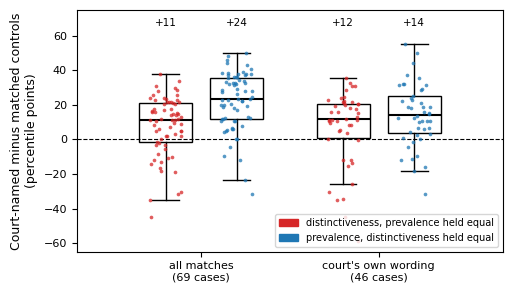

saved fig_court_matched


In [23]:
CL = read_parquet(V4 / '07c_court_matcher_v2' / 'baselines_v2_by_case.parquet')
CL = CL[CL['baseline'] == 'matched_controls']
STRICT = 'strict (exact + phrase + event)'
groups = [('all tiers', 'all matches'), (STRICT, "court's own wording")]
fig, ax = plt.subplots(figsize=S.size(0.8, 3.0))
jit = np.random.default_rng(SEED)
for gi, (st, _) in enumerate(groups):
    for off, k, meas in [(-0.2, 'distinctiveness', 'distinctiveness_given_prevalence'), (0.2, 'prevalence', 'prevalence_given_distinctiveness')]:
        v = 100 * CL[(CL['set'] == st) & (CL['measure'] == meas)]['value'].values
        ax.boxplot(v, positions=[gi + off], widths=0.3, showfliers=False, patch_artist=True,
                   boxprops=dict(facecolor='white', edgecolor=S.INK), medianprops=dict(color=S.INK, lw=1.5),
                   whiskerprops=dict(color=S.INK), capprops=dict(color=S.INK))
        ax.scatter(gi + off + jit.uniform(-0.09, 0.09, len(v)), v, s=7, color=color_of(k), alpha=0.75, zorder=3, lw=0)
        ax.text(gi + off, 66, f'{np.median(v):+.0f}', ha='center', fontsize=7.5)
        print(st, meas, 'cases', len(v), 'median', round(np.median(v), 1), 'above zero', int((v > 0).sum()))
ax.axhline(0, color=S.INK, ls='--', lw=0.8)
n_cases = [int(((CL['set'] == st) & (CL['measure'] == 'distinctiveness_given_prevalence')).sum()) for st, _ in groups]
ax.set_xticks([0, 1]); ax.set_xticklabels([f'{lbl}\n({n} cases)' for (st, lbl), n in zip(groups, n_cases)])
ax.set_ylim(-65, 75); ax.set_ylabel('Court-named minus matched controls\n(percentile points)')
ax.legend(handles=[Patch(color=RED, label='distinctiveness, prevalence held equal'),
                   Patch(color=BLUE, label='prevalence, distinctiveness held equal')], loc='lower right', fontsize=7)
save(fig, 'fig_court_matched')

## Figure: how the court phrases were matched

The stricter matcher of Notebook 07c tries the court's exact phrase, then its longest multi-word part found in the corpus, then an event found by the parser, then the grammatical head (a single noun), and otherwise declines. The first three keep the court's own wording.

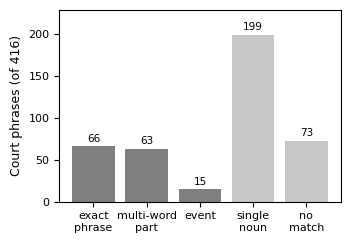

saved fig_matcher_tiers
tier
exact        66
phrase       63
event        15
head        199
declined     73


In [24]:
sheet = pd.read_csv(V4 / '07c_court_matcher_v2' / 'match_review_sheet_v2.csv')
cov = sheet['tier'].value_counts()
order_t = ['exact', 'phrase', 'event', 'head', 'declined']
names = {'exact': 'exact\nphrase', 'phrase': 'multi-word\npart', 'event': 'event', 'head': 'single\nnoun', 'declined': 'no\nmatch'}
fig, ax = plt.subplots(figsize=S.size(0.55, 2.5))
ax.bar(range(5), [cov.get(t, 0) for t in order_t], color=[GRAY, GRAY, GRAY, LIGHT, LIGHT])
for i, t in enumerate(order_t):
    ax.text(i, cov.get(t, 0) + 3, str(int(cov.get(t, 0))), ha='center', va='bottom', fontsize=7.5)
ax.set_xticks(range(5)); ax.set_xticklabels([names[t] for t in order_t]); ax.set_ylim(0, cov.max() * 1.15)
ax.set_ylabel(f'Court phrases (of {len(sheet)})')
save(fig, 'fig_matcher_tiers')
print(cov.reindex(order_t).to_string())

## Courts, the simpler figures (Nov 12, 2026)

The same three questions as the talk's court slides, drawn in the manuscript style.

1. **Where court-named features sit on the two numbers.** Features matched in the court's own wording (Notebook 07c's strict set: exact phrase, multi-word part, or event), placed by their percentiles on prevalence and on distinctiveness within the court's genre; dashed lines at the 75th percentile.
2. **Is the court's genre the feature's best genre?** The share of court-named features (07b, story features in the court's genre) whose court genre ranks first among the genres containing the feature, by each measure, against the chance share (the mean of 1/k over features found in k genres). Wilson 95% intervals.
3. **Matched controls.** Per case, the court-named features' distinctiveness minus that of equally common controls, and their prevalence minus that of equally characteristic controls (same genre and type, within two percentile points, at least five controls, court-named items excluded), in percentile points; bar = median over cases with a bootstrap 95% interval; dots = cases.

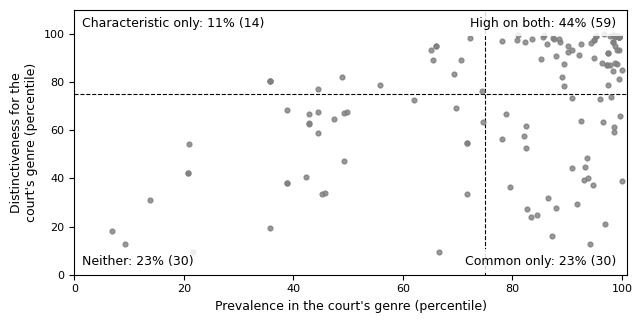

saved fig_court_quadrant
{'High on both': (59, 0.444), 'Common only': (30, 0.226), 'Characteristic only': (14, 0.105), 'Neither': (30, 0.226)} | features 133 | cases 46


In [25]:
sm = read_parquet(V4 / '07c_court_matcher_v2' / 'scored_matches_v2.parquet')
st = sm[sm.tier.isin(['exact', 'phrase', 'event']) & (sm.label == 'held_stock')].dropna(subset=['p_prevalence', 'p_distinctiveness'])
assert len(st) == 133 and st.case.nunique() == 46
hp, hd = st.p_prevalence >= .75, st.p_distinctiveness >= .75
fig, ax = plt.subplots(figsize=S.size(1.0, 3.3))
ax.scatter(100 * st.p_prevalence, 100 * st.p_distinctiveness, s=12, color=GRAY, alpha=0.8, zorder=3)
ax.axvline(75, color=S.INK, ls='--', lw=0.8); ax.axhline(75, color=S.INK, ls='--', lw=0.8)
quad = [('High on both', hp & hd, 99, 101.5, 'right'), ('Common only', hp & ~hd, 99, 3, 'right'),
        ('Characteristic only', ~hp & hd, 1.5, 101.5, 'left'), ('Neither', ~hp & ~hd, 1.5, 3, 'left')]
for lab, m, tx, ty, ha in quad:
    ax.text(tx, ty, f'{lab}: {m.mean():.0%} ({m.sum()})', ha=ha, va='bottom', bbox=dict(facecolor='white', edgecolor='none', alpha=0.85))
ax.set_xlim(0, 101); ax.set_ylim(0, 110)
ax.set_xlabel("Prevalence in the court's genre (percentile)"); ax.set_ylabel("Distinctiveness for the\ncourt's genre (percentile)")
save(fig, 'fig_court_quadrant')
print({lab: (int(m.sum()), round(float(m.mean()), 3)) for lab, m, *_ in quad}, '| features', len(st), '| cases', st.case.nunique())

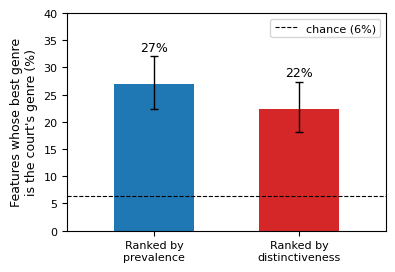

saved fig_court_top_genre
n 312 | cases 68 | top genre {'prevalence': 0.269, 'distinctiveness': 0.224} | chance 0.064


In [26]:
db = read_parquet(V4 / '07b_court_validation' / 'dimension_baselines.parquet')
r = db[(db.baseline == 'court_genre_rank') & (db.subset == 'narrative_in_genre')].set_index('measure')
n = int(r.loc['prevalence', 'n_elements']); chance = float(r.loc['prevalence', 'top_genre_chance'])
fig, ax = plt.subplots(figsize=S.size(0.62, 2.8))
for i, m in enumerate(['prevalence', 'distinctiveness']):
    p = float(r.loc[m, 'top_genre_share']); k = round(p * n); lo, hi = wilson(k, n)
    ax.bar(i, 100 * p, 0.55, color=COL[m], yerr=[[100 * (p - float(lo))], [100 * (float(hi) - p)]], error_kw=S.ERR)
    ax.text(i, 100 * float(hi) + 1.0, f'{p:.0%}', ha='center')
ax.axhline(100 * chance, color=S.INK, ls='--', lw=0.8, label=f'chance ({chance:.0%})')
ax.legend(loc='upper right')
ax.set_xticks([0, 1]); ax.set_xticklabels(['Ranked by\nprevalence', 'Ranked by\ndistinctiveness']); ax.set_xlim(-0.6, 1.6); ax.set_ylim(0, 40)
ax.set_ylabel("Features whose best genre\nis the court's genre (%)")
save(fig, 'fig_court_top_genre')
print('n', n, '| cases', int(r.loc['prevalence', 'n_cases']), '| top genre', r.loc[['prevalence', 'distinctiveness'], 'top_genre_share'].round(3).to_dict(), '| chance', round(chance, 3))

distinctiveness_given_prevalence median 11.7 CI 8.3 18.5 cases above zero 34 of 46


prevalence_given_distinctiveness median 14.1 CI 10.3 19.1 cases above zero 37 of 46


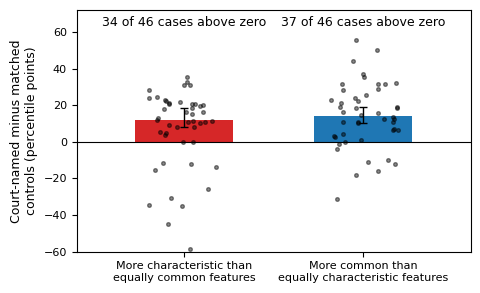

saved fig_court_vs_controls


In [27]:
bc2 = read_parquet(V4 / '07c_court_matcher_v2' / 'baselines_v2_by_case.parquet')
mc = bc2[(bc2.set == 'strict (exact + phrase + event)') & (bc2.baseline == 'matched_controls')]
rng = np.random.default_rng(SEED)
fig, ax = plt.subplots(figsize=S.size(0.75, 3.0))
for i, (m, col) in enumerate([('distinctiveness_given_prevalence', RED), ('prevalence_given_distinctiveness', BLUE)]):
    v = 100 * mc[mc.measure == m].value.to_numpy(); med = np.median(v)
    lo, hi = np.percentile([np.median(rng.choice(v, len(v))) for _ in range(5000)], [2.5, 97.5])
    ax.bar(i, med, 0.55, color=col, yerr=[[med - lo], [hi - med]], error_kw=S.ERR, zorder=2)
    ax.scatter(i + rng.uniform(-0.2, 0.2, len(v)), v, s=7, color=S.INK, alpha=0.45, zorder=3)
    ax.text(i, 63, f'{(v > 0).sum()} of {len(v)} cases above zero', ha='center')
    print(m, 'median', round(med, 1), 'CI', round(lo, 1), round(hi, 1), 'cases above zero', int((v > 0).sum()), 'of', len(v))
ax.axhline(0, color=S.INK, lw=0.8)
ax.set_xticks([0, 1]); ax.set_xticklabels(['More characteristic than\nequally common features', 'More common than\nequally characteristic features'])
ax.set_xlim(-0.6, 1.6); ax.set_ylim(-60, 72)
ax.set_ylabel('Court-named minus matched\ncontrols (percentile points)')
save(fig, 'fig_court_vs_controls')

## Files written

In [28]:
for p in sorted(FIG.glob('fig_*.pdf')):
    if p.stat().st_mtime > __import__('time').time() - 3600 * 6: print(p.name)
for p in sorted(TAB.glob('T-*.tex')):
    if p.name.startswith(('T-III-corpus', 'T-III-extraction', 'T-III-validation', 'T-IV-top5', 'T-App-A_top10')): print(p.name)

fig_app_lifecycles_by_genre.pdf
fig_app_network_Action.pdf
fig_app_network_Adventure.pdf
fig_app_network_Animation.pdf
fig_app_network_Comedy.pdf
fig_app_network_Crime.pdf
fig_app_network_Drama.pdf
fig_app_network_Family.pdf
fig_app_network_Fantasy.pdf
fig_app_network_History.pdf
fig_app_network_Horror.pdf
fig_app_network_Music.pdf
fig_app_network_Mystery.pdf
fig_app_network_Romance.pdf
fig_app_network_Science_Fiction.pdf
fig_app_network_Thriller.pdf
fig_app_network_War.pdf
fig_app_network_Western.pdf
fig_app_survival_by_genre.pdf
fig_app_turnover_by_genre.pdf
fig_centrality_two_measures.pdf
fig_change_points.pdf
fig_classifier_check.pdf
fig_corpus_genres.pdf
fig_court_genre_rank.pdf
fig_court_matched.pdf
fig_court_quadrant.pdf
fig_court_top_genre.pdf
fig_court_vs_controls.pdf
fig_courts_percentiles.pdf
fig_events_both_dimensions.pdf
fig_events_three_genres.pdf
fig_events_three_more.pdf
fig_extraction_recall.pdf
fig_heldout_by_genre.pdf
fig_heldout_prediction.pdf
fig_lifecycles_six.pdf